# 18 · Reinforcement Learning — Learning by Trial and Error

Supervised learning has an answer key. **Reinforcement learning (RL)** doesn't: an **agent** takes **actions** in an **environment**, receives **rewards**, and must work out from experience which actions lead to the most reward *over time*. It's how game-playing agents (AlphaGo), robot controllers and recommendation policies are trained — and the "RL" in **RLHF**, which tunes chat assistants (notebook 17).

**What you'll learn**
1. **Multi-armed bandits:** the exploration–exploitation trade-off (ε-greedy, UCB, Thompson sampling)
2. **Markov decision processes (MDPs):** states, actions, rewards, discounting, policies and value functions
3. The **Bellman equations**, and **value iteration / policy iteration** when the environment is known
4. Learning from experience: **Monte Carlo** vs **temporal-difference** learning
5. **Q-learning vs SARSA** on the cliff — off-policy vs on-policy
6. **Policy gradients (REINFORCE)** with a neural network on CartPole (simulator written from scratch)
7. The map of modern deep RL: DQN, actor-critic, PPO, and RLHF

Everything runs on environments we write ourselves — no extra libraries needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random, time
import torch
from torch import nn
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); random.seed(0); torch.manual_seed(0)

## 1. Multi-armed bandits — RL with one state

You face k slot machines ("one-armed bandits"), each paying out with an unknown probability. Each round you pull one. Goal: **maximise total reward**. The dilemma:
- **Exploit:** pull the arm that looks best so far.
- **Explore:** try other arms — one of them might be better.

Pure exploitation can lock onto a mediocre arm forever; pure exploration wastes pulls. Real examples: which ad to show, which headline to test, which treatment to give (adaptive trials).

**Regret** = reward you'd have got always pulling the best arm − reward you actually got. Good algorithms have regret that grows only **logarithmically** with time.

Three classic strategies:
- **ε-greedy:** exploit, but with probability ε pick a random arm.
- **UCB (upper confidence bound):** pick the arm with the highest *optimistic* estimate $\hat\mu_a + c\sqrt{\ln t / n_a}$ — rarely-tried arms get a bonus ("optimism in the face of uncertainty").
- **Thompson sampling:** keep a Beta posterior per arm (notebook 13), draw one sample from each, pull the arm whose sample is highest. Explores exactly as much as its uncertainty warrants.

In [2]:
true_p = np.array([0.20, 0.25, 0.30, 0.45, 0.50])          # arm 4 is best, but arm 3 is close

# 🐍 Pure Python ε-greedy
def eps_greedy_python(p, steps, eps=0.1, seed=0):
    r = random.Random(seed); n = [0] * len(p); val = [0.0] * len(p); total = 0
    for t in range(steps):
        a = r.randrange(len(p)) if r.random() < eps else max(range(len(p)), key=lambda i: val[i])
        reward = 1 if r.random() < p[a] else 0
        n[a] += 1; val[a] += (reward - val[a]) / n[a]               # running mean update
        total += reward
    return total, n

total, counts = eps_greedy_python(true_p.tolist(), 5000)
print(f"ε-greedy: total reward {total} | pulls per arm {counts}")

ε-greedy: total reward 2398 | pulls per arm [181, 124, 94, 107, 4494]


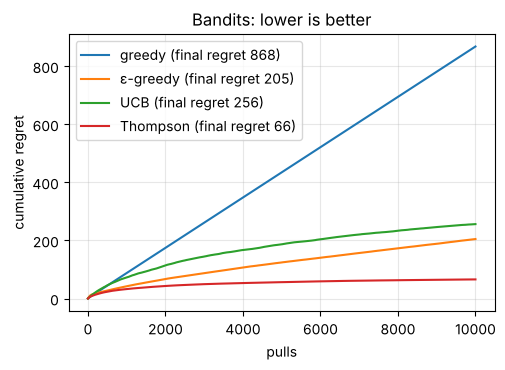

In [3]:
# 🔢 NumPy versions of all three, with regret curves averaged over many runs
def run_bandit(policy, p, steps=10_000, seed=0):
    r = np.random.default_rng(seed); k = len(p); n = np.zeros(k); s = np.zeros(k); regret = np.zeros(steps)
    for t in range(steps):
        if policy == "greedy":       a = np.argmax(s / np.maximum(n, 1)) if t >= k else t
        elif policy == "ε-greedy":   a = r.integers(k) if r.random() < 0.1 else np.argmax(s / np.maximum(n, 1))
        elif policy == "UCB":        a = t if t < k else np.argmax(s / n + np.sqrt(2 * np.log(t) / n))
        elif policy == "Thompson":   a = np.argmax(r.beta(1 + s, 1 + n - s))
        reward = r.random() < p[a]; n[a] += 1; s[a] += reward
        regret[t] = p.max() - p[a]
    return np.cumsum(regret)

for pol in ["greedy", "ε-greedy", "UCB", "Thompson"]:
    curves = np.array([run_bandit(pol, true_p, seed=s) for s in range(30)])
    plt.plot(curves.mean(0), label=f"{pol} (final regret {curves.mean(0)[-1]:.0f})")
plt.xlabel("pulls"); plt.ylabel("cumulative regret"); plt.legend(); plt.title("Bandits: lower is better"); plt.show()

- **Greedy** gets stuck on whichever arm got lucky early → regret grows linearly forever.
- **ε-greedy** keeps exploring at a fixed 10% rate forever → also linear, just with a smaller slope.
- **UCB** explores a lot at first: the two best arms (0.45 and 0.50) are hard to tell apart, and its textbook confidence bonus is deliberately conservative. Its curve **bends**, though. Regret grows only logarithmically, so given a long enough horizon it overtakes any fixed ε, even though it hasn't by 10,000 pulls. Tuning the bonus constant down speeds it up.
- **Thompson sampling** explores exactly as much as its uncertainty warrants and is best here — the usual winner in practice.

## 2. Markov decision processes

Bandits have one state. In general, actions change the **state** of the world, and rewards may come much later (a chess move pays off 40 moves on). The framework:

- **States** $s$, **actions** $a$, **transition probabilities** $P(s' \mid s, a)$, **rewards** $R(s, a)$.
- **Markov property:** the next state depends only on the current state and action, not the history.
- A **policy** $\pi(a \mid s)$: how the agent chooses actions.
- The **return** $G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$ — future rewards **discounted** by γ ∈ [0, 1) (a reward now is worth more than later; also keeps sums finite).
- **Value functions:** $V^\pi(s)$ = expected return starting in s and following π; $Q^\pi(s, a)$ = expected return after taking a in s, then following π.

### A gridworld
The agent moves up/down/left/right on a grid. Moves are **slippery**: 80% go where intended, 10% each slip sideways. Reaching the goal gives +1, falling in a pit −1, every step costs −0.04 (so dawdling is bad).

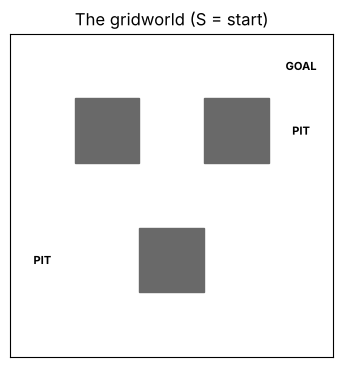

In [4]:
GRID = ["....G",
        ".#.#P",
        ".....",
        "P.#..",
        "S...."]
ROWS, COLS = len(GRID), len(GRID[0])
ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}         # up, right, down, left
ARROWS = {0: "↑", 1: "→", 2: "↓", 3: "←"}
STATES = [(r, c) for r in range(ROWS) for c in range(COLS) if GRID[r][c] != "#"]
TERMINAL = {(r, c): (1.0 if GRID[r][c] == "G" else -1.0) for r, c in STATES if GRID[r][c] in "GP"}
STEP_COST = -0.04

def move(s, a):
    r, c = s[0] + ACTIONS[a][0], s[1] + ACTIONS[a][1]
    return (r, c) if 0 <= r < ROWS and 0 <= c < COLS and GRID[r][c] != "#" else s   # walls: stay put

def transitions(s, a):
    """List of (probability, next_state, reward). 80% intended, 10% each perpendicular."""
    out = []
    for prob, act in [(0.8, a), (0.1, (a + 1) % 4), (0.1, (a + 3) % 4)]:
        s2 = move(s, act)
        out.append((prob, s2, TERMINAL.get(s2, STEP_COST)))
    return out

def show_grid(V=None, policy=None, title=""):
    fig, ax = plt.subplots(figsize=(5, 4.2)); M = np.full((ROWS, COLS), np.nan)
    if V is not None:
        for s in STATES: M[s] = V.get(s, 0)
    ax.imshow(M, cmap="RdYlGn", vmin=-1, vmax=1)
    for r in range(ROWS):
        for c in range(COLS):
            ch = GRID[r][c]
            if ch == "#": ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="dimgray"))
            elif ch in "GP": ax.text(c, r, "GOAL" if ch == "G" else "PIT", ha="center", va="center", fontsize=8, weight="bold")
            else:
                txt = (ARROWS[policy[(r, c)]] if policy else "") + (f"\n{V[(r, c)]:.2f}" if V is not None else "")
                ax.text(c, r, txt, ha="center", va="center", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title); plt.show()

show_grid(title="The gridworld (S = start)")

## 3. The Bellman equations and dynamic programming

The value of a state = immediate reward + discounted value of where you land. For the **optimal** values:
$$ V^*(s) = \max_a \sum_{s'} P(s' \mid s, a)\,\big[R + \gamma V^*(s')\big] \qquad \text{(Bellman optimality equation)} $$
When the transition probabilities are **known**, we can solve this directly — **dynamic programming**:

- **Value iteration:** start with V = 0 and repeatedly apply the equation above as an update until values stop changing. Then act greedily: pick the action with the best expected value.
- **Policy iteration:** alternate **evaluating** the current policy (compute $V^\pi$) and **improving** it (act greedily w.r.t. $V^\pi$). Usually converges in very few iterations.

value iteration converged in 24 sweeps


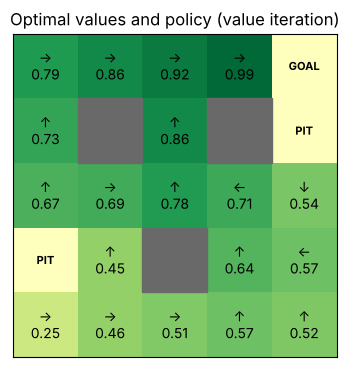

In [5]:
# 🐍 Pure Python value iteration
def q_value(V, s, a, gamma):
    return sum(p * (r + gamma * (0 if s2 in TERMINAL else V[s2])) for p, s2, r in transitions(s, a))

def value_iteration(gamma=0.99, tol=1e-6):
    V = {s: 0.0 for s in STATES}; sweeps = 0
    while True:
        delta = 0.0; sweeps += 1
        for s in STATES:
            if s in TERMINAL: continue
            best = max(q_value(V, s, a, gamma) for a in ACTIONS)
            delta = max(delta, abs(best - V[s])); V[s] = best
        if delta < tol: break
    policy = {s: max(ACTIONS, key=lambda a: q_value(V, s, a, gamma)) for s in STATES if s not in TERMINAL}
    return V, policy, sweeps

V_vi, pi_vi, sweeps = value_iteration()
print(f"value iteration converged in {sweeps} sweeps")
show_grid(V_vi, pi_vi, "Optimal values and policy (value iteration)")

In [6]:
# 🐍 Policy iteration
def policy_iteration(gamma=0.99):
    policy = {s: 0 for s in STATES if s not in TERMINAL}; rounds = 0
    while True:
        rounds += 1; V = {s: 0.0 for s in STATES}
        for _ in range(500):                                      # policy evaluation (iterative)
            for s in policy: V[s] = q_value(V, s, policy[s], gamma)
        new = {s: max(ACTIONS, key=lambda a: q_value(V, s, a, gamma)) for s in policy}   # improvement
        if new == policy: return V, policy, rounds
        policy = new

V_pi, pi_pi, rounds = policy_iteration()
print(f"policy iteration converged in {rounds} rounds; same policy as value iteration: {pi_pi == pi_vi}")

policy iteration converged in 6 rounds; same policy as value iteration: True


Notice the policy near the pits: it takes the **long, safe route** — because moves are slippery, walking alongside a pit risks a 10% slip into it. The agent has learned to trade path length against risk.

## 4. Learning without a model: Monte Carlo vs temporal difference

Usually we **don't know** $P(s' \mid s, a)$ — we can only *try things* and observe what happens. Two ways to estimate values from experience:

- **Monte Carlo (MC):** play a whole episode, then update each visited state toward the **actual return** $G_t$. Unbiased, but high variance, and must wait until the episode ends.
- **Temporal difference (TD(0)):** after *each step*, update toward a **bootstrapped** target — the reward plus the current *estimate* of the next state:
$$ V(s) \leftarrow V(s) + \alpha\,\big[\,r + \gamma V(s') - V(s)\,\big] $$
The bracket is the **TD error**: "how surprised was I?" Biased (it uses an estimate), but lower variance and learns online. This one idea underlies Q-learning, DQN and actor-critic methods.

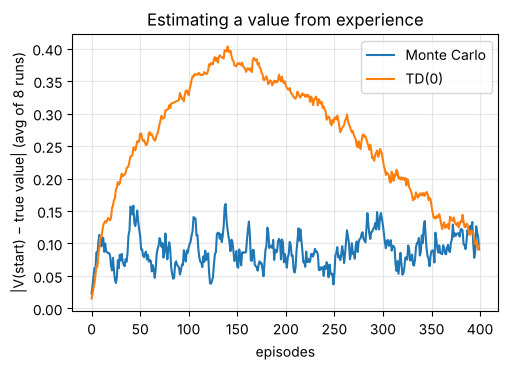

In [7]:
def run_episode(policy, eps=0.0, seed=None, max_steps=200):
    r = random.Random(seed); s = (4, 0); traj = []
    for _ in range(max_steps):
        a = r.randrange(4) if r.random() < eps else policy[s]
        p, s2, rew = r.choices(transitions(s, a), weights=[t[0] for t in transitions(s, a)])[0]
        traj.append((s, a, rew, s2)); s = s2
        if s in TERMINAL: break
    return traj

def mc_evaluate(policy, episodes, gamma=0.99, alpha=0.05, seed0=0):
    V = {s: 0.0 for s in STATES}; errs = []
    for ep in range(episodes):
        G = 0.0
        for s, a, rew, s2 in reversed(run_episode(policy, eps=0.2, seed=seed0 + ep)):
            G = rew + gamma * G; V[s] += alpha * (G - V[s])           # move toward the actual return
        errs.append(abs(V[(4, 0)] - V_true[(4, 0)]))
    return V, errs

def td_evaluate(policy, episodes, gamma=0.99, alpha=0.05, seed0=0):
    V = {s: 0.0 for s in STATES}; errs = []
    for ep in range(episodes):
        for s, a, rew, s2 in run_episode(policy, eps=0.2, seed=seed0 + ep):
            target = rew + gamma * (0 if s2 in TERMINAL else V[s2])
            V[s] += alpha * (target - V[s])                          # move toward the bootstrapped target
        errs.append(abs(V[(4, 0)] - V_true[(4, 0)]))
    return V, errs

# The "true" value of the start state under the ε-soft version of the optimal policy, by many long MC rollouts
V_true = {(4, 0): np.mean([sum(0.99 ** t * x[2] for t, x in enumerate(run_episode(pi_vi, eps=0.2, seed=10_000 + i))) for i in range(4000)])}
err_mc = np.mean([mc_evaluate(pi_vi, 400, seed0=1000 * k)[1] for k in range(8)], axis=0)
err_td = np.mean([td_evaluate(pi_vi, 400, seed0=1000 * k)[1] for k in range(8)], axis=0)
plt.plot(err_mc, label="Monte Carlo"); plt.plot(err_td, label="TD(0)")
plt.xlabel("episodes"); plt.ylabel("|V(start) − true value| (avg of 8 runs)"); plt.legend(); plt.title("Estimating a value from experience"); plt.show()

Two things to notice:
- **TD first drifts away, then converges.** All values begin at 0, and each TD update looks only one step ahead, so the start square learns from neighbours whose values are still wrong. The steady −0.04 step costs and the nearby pit propagate back before the distant goal's reward has reached the start, which drags the estimate down. Information travels backwards **one state per visit**. Monte Carlo uses real returns from the start.
- **Monte Carlo stays noisier.** A single episode's return varies a lot (a slip near a pit changes everything). TD's targets average over that randomness, so once the values have propagated its estimate is steadier.

That's the **bias–variance trade-off** again (notebook 03): TD is biased by its own estimates but has low variance; MC is unbiased but high-variance. Methods like n-step TD and TD(λ) sit in between.

## 5. Control: Q-learning vs SARSA on the cliff

To **choose** actions without a model, learn **Q(s, a)** directly and act greedily on it.
- **SARSA** (on-policy): update toward $r + \gamma Q(s', a')$, where $a'$ is the action the agent **actually** takes next (including exploratory ones).
- **Q-learning** (off-policy): update toward $r + \gamma \max_{a'} Q(s', a')$ — the **best** next action, regardless of what the agent does.

The classic **cliff walk** shows the difference: walk from S to G along a cliff edge; stepping into the cliff costs −100 and sends you back to the start. Every step costs −1.

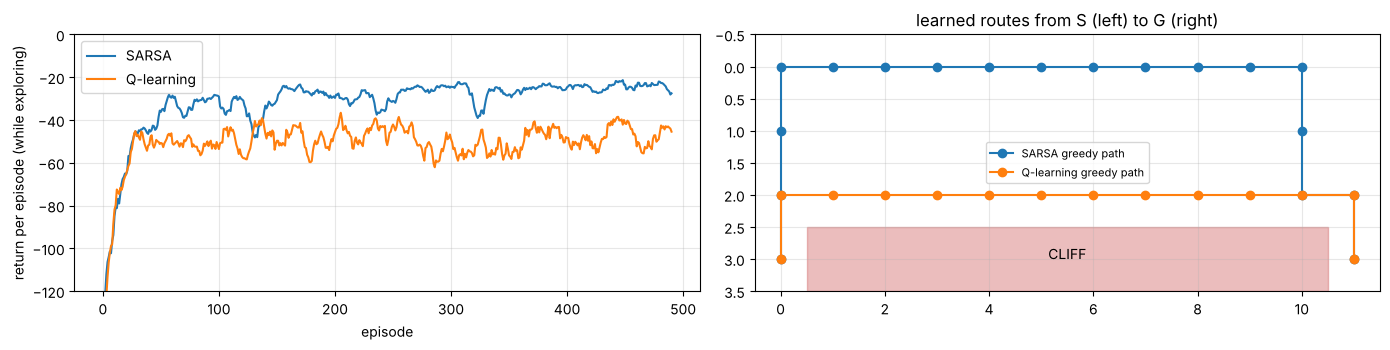

In [8]:
CR, CC = 4, 12; CSTART, CGOAL = (3, 0), (3, 11)
def cliff_step(s, a):
    r, c = s[0] + ACTIONS[a][0], s[1] + ACTIONS[a][1]
    r, c = min(max(r, 0), CR - 1), min(max(c, 0), CC - 1)
    if r == 3 and 0 < c < 11: return CSTART, -100, False             # fell off the cliff
    return (r, c), -1, (r, c) == CGOAL

def td_control(method, episodes=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    r = np.random.default_rng(seed); Q = np.zeros((CR, CC, 4)); returns = []
    pick = lambda s: r.integers(4) if r.random() < eps else int(np.argmax(Q[s]))
    for _ in range(episodes):
        s, a, total = CSTART, None, 0
        a = pick(s)
        for _ in range(500):
            s2, rew, done = cliff_step(s, a); total += rew
            a2 = pick(s2)
            target = rew + (0 if done else gamma * (Q[s2][a2] if method == "SARSA" else Q[s2].max()))
            Q[s][a] += alpha * (target - Q[s][a])
            s, a = s2, a2
            if done: break
        returns.append(total)
    return Q, np.array(returns)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for method in ["SARSA", "Q-learning"]:
    runs = [td_control(method, seed=k) for k in range(20)]
    ax[0].plot(np.convolve(np.mean([r_[1] for r_ in runs], 0), np.ones(10) / 10, "valid"), label=method)
    Q = runs[0][0]; s = CSTART; path = [s]
    for _ in range(40):
        s, _, done = cliff_step(s, int(np.argmax(Q[s]))); path.append(s)
        if done: break
    ys, xs = zip(*path); ax[1].plot(xs, ys, "o-", label=f"{method} greedy path")
ax[0].set_ylim(-120, 0); ax[0].set_xlabel("episode"); ax[0].set_ylabel("return per episode (while exploring)"); ax[0].legend()
ax[1].add_patch(plt.Rectangle((0.5, 2.5), 10, 1, color="indianred", alpha=0.4)); ax[1].text(5.5, 3, "CLIFF", ha="center")
ax[1].set_xlim(-0.5, 11.5); ax[1].set_ylim(3.5, -0.5); ax[1].legend(fontsize=8); ax[1].set_title("learned routes from S (left) to G (right)")
plt.tight_layout(); plt.show()

- **Q-learning** learns the **optimal** route — right along the cliff edge — because its target assumes perfect future play. But while it's still exploring (ε = 0.1), it occasionally steps off the cliff, so its *training* returns are worse.
- **SARSA** learns that *it* will sometimes take random steps, so it prefers the **safer** route one row up, earning more reward during learning.

Which is right depends on whether exploration mistakes cost real money — a robot falling off a real cliff argues for SARSA-like caution.

**Other key ideas in tabular RL** (see the notes): *n-step* returns and *TD(λ)* blend MC and TD; *Double Q-learning* fixes the overestimation caused by the max; *Dyna-Q* mixes real experience with planning on a learned model.

## 6. Policy gradients with a neural network — CartPole

Tables don't scale to large or continuous state spaces. Two families use neural networks:
- **Value-based** (DQN): a network approximates Q(s, a); act greedily.
- **Policy-based**: a network outputs the **policy** π(a | s) directly, and we adjust its weights to make high-return actions more likely.

**REINFORCE** — the simplest policy gradient. The **policy gradient theorem** gives
$$ \nabla_\theta J = \mathbb{E}\left[\sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\, G_t\right] $$
In words: increase the log-probability of each action **in proportion to the return that followed it**. Subtracting a **baseline** (e.g. the average return) doesn't change the expected gradient but greatly reduces its variance.

**CartPole:** balance a pole on a cart by pushing left or right. +1 reward per step the pole stays up (max 500). We write the physics ourselves (the standard equations from Barto, Sutton & Anderson, 1983).

In [9]:
class CartPole:
    """Classic cart-pole physics. State: cart position, cart velocity, pole angle, pole angular velocity."""
    gravity, m_cart, m_pole, length, force, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, seed=0): self.rng = np.random.default_rng(seed)
    def reset(self):
        self.state = self.rng.uniform(-0.05, 0.05, 4); self.t = 0; return self.state.copy()
    def step(self, action):
        x, x_dot, th, th_dot = self.state
        f = self.force if action == 1 else -self.force
        cos, sin = math.cos(th), math.sin(th); total = self.m_cart + self.m_pole; pml = self.m_pole * self.length
        temp = (f + pml * th_dot ** 2 * sin) / total
        th_acc = (self.gravity * sin - cos * temp) / (self.length * (4 / 3 - self.m_pole * cos ** 2 / total))
        x_acc = temp - pml * th_acc * cos / total
        x, x_dot, th, th_dot = x + self.dt * x_dot, x_dot + self.dt * x_acc, th + self.dt * th_dot, th_dot + self.dt * th_acc
        self.state = np.array([x, x_dot, th, th_dot]); self.t += 1
        done = abs(x) > 2.4 or abs(th) > 12 * math.pi / 180 or self.t >= 500
        return self.state.copy(), 1.0, done

env = CartPole(seed=0)
random_lengths = []
for _ in range(100):
    env.reset(); done, n = False, 0
    while not done: _, _, done = env.step(random.randrange(2)); n += 1
    random_lengths.append(n)
print(f"random policy keeps the pole up for {np.mean(random_lengths):.1f} steps on average")

random policy keeps the pole up for 23.2 steps on average


trained 400 episodes in 18s


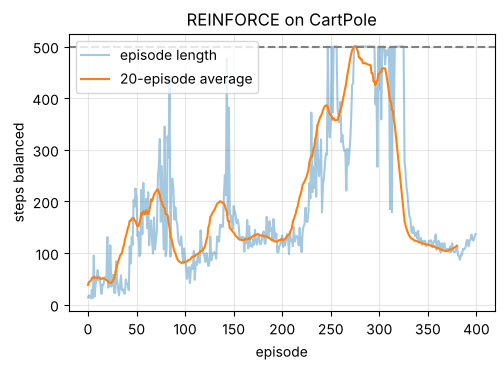

In [10]:
def reinforce(episodes=400, lr=1e-2, gamma=0.99, seed=0):
    torch.manual_seed(seed); env = CartPole(seed)
    policy = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 2))      # state → action logits
    opt = torch.optim.Adam(policy.parameters(), lr=lr); lengths, best, best_state = [], 0, None
    for ep in range(episodes):
        s = env.reset(); log_probs, rewards, done = [], [], False
        while not done:
            dist = torch.distributions.Categorical(logits=policy(torch.tensor(s, dtype=torch.float32)))
            a = dist.sample(); log_probs.append(dist.log_prob(a))
            s, r, done = env.step(a.item()); rewards.append(r)
        G, returns = 0.0, []
        for r in reversed(rewards):                       # discounted return from each step
            G = r + gamma * G; returns.insert(0, G)
        returns = torch.tensor(returns)
        advantage = (returns - returns.mean()) / (returns.std() + 1e-8)       # baseline + scaling → lower variance
        loss = -(torch.stack(log_probs) * advantage).sum()                     # gradient ASCENT on expected return
        opt.zero_grad(); loss.backward(); opt.step()
        lengths.append(len(rewards))
        recent = np.mean(lengths[-20:])
        if recent > best: best, best_state = recent, {k: v.clone() for k, v in policy.state_dict().items()}
    policy.load_state_dict(best_state)
    return policy, lengths

t0 = time.perf_counter(); policy, lengths = reinforce()
print(f"trained {len(lengths)} episodes in {time.perf_counter() - t0:.0f}s")
plt.plot(lengths, alpha=0.4, label="episode length"); plt.plot(np.convolve(lengths, np.ones(20) / 20, "valid"), label="20-episode average")
plt.axhline(500, ls="--", c="gray"); plt.xlabel("episode"); plt.ylabel("steps balanced"); plt.legend(); plt.title("REINFORCE on CartPole"); plt.show()

In [11]:
# Evaluate the best policy greedily (no sampling)
env_eval = CartPole(seed=123); scores = []
for _ in range(20):
    s = env_eval.reset(); done, n = False, 0
    while not done:
        with torch.no_grad(): a = int(policy(torch.tensor(s, dtype=torch.float32)).argmax())
        s, _, done = env_eval.step(a); n += 1
    scores.append(n)
print(f"greedy evaluation over 20 new episodes: mean {np.mean(scores):.0f} steps (max 500) vs random {np.mean(random_lengths):.0f}")

greedy evaluation over 20 new episodes: mean 500 steps (max 500) vs random 23


The learning curve is **noisy and can collapse** after reaching good performance — a known weakness of plain REINFORCE: one unlucky large update can wreck a good policy. (That's why we kept the best weights seen.) The fixes are the core of modern deep RL:

## 7. The modern deep-RL map

| Method | Idea | Used for |
|---|---|---|
| **DQN** (2015) | neural Q-function + **experience replay** (re-use past transitions) + a **target network** (stable targets) | Atari from pixels |
| **Actor-critic / A2C** | a **critic** learns V(s); the **actor** uses the advantage $r + \gamma V(s') - V(s)$ instead of full returns → lower variance | the basis of most modern methods |
| **GAE** | a tunable blend between TD and Monte Carlo advantages | variance/bias control |
| **TRPO / PPO** | limit how far each update can move the policy (PPO clips the probability ratio) → stable training | robotics, games, **RLHF** |
| **SAC, TD3** | off-policy actor-critic for continuous actions | robot control |
| **Model-based** (Dyna, MuZero) | learn a model of the environment and plan with it | sample efficiency, board games |
| **Offline RL** | learn only from a fixed dataset, without new interaction | healthcare, recommendations |

**The deadly triad:** combining *function approximation* + *bootstrapping* + *off-policy learning* can make values diverge — DQN's replay buffer and target network exist to tame it.

### RLHF — the RL most people now use without knowing it
1. Collect human preferences between pairs of model answers.
2. Train a **reward model** to predict which answer humans prefer.
3. Fine-tune the language model with **PPO** to maximise that reward, plus a penalty (KL divergence) for drifting too far from the original model — otherwise it learns to "hack" the reward model.
Here the "state" is the conversation so far, an "action" is the next token, and the reward arrives at the end of the answer. DPO (notebook 17) achieves similar results without the RL loop.

### Practical RL checklist
- Start with the simplest thing: a bandit, a heuristic, or supervised learning on good demonstrations (imitation learning).
- Reward design is everything — agents exploit loopholes (**reward hacking**).
- RL is noisy: use several random seeds, plot averages with spread, normalise observations and advantages.
- Check that a random policy and a hand-coded policy give the scores you expect before training.

## Key takeaways
- RL learns from rewards via interaction; the core tension is **exploration vs exploitation**.
- Bandits: UCB and Thompson sampling explore efficiently (log regret).
- MDP + Bellman equation: value = reward + discounted value of what follows. With a known model, value/policy iteration solve it.
- Without a model: Monte Carlo uses full returns; TD bootstraps from estimates (the TD error).
- Q-learning (off-policy) learns the optimal policy; SARSA (on-policy) learns a policy that's safe given its own exploration.
- Policy gradients push up the log-probability of actions in proportion to their (baseline-subtracted) return; PPO stabilises this and powers RLHF.

## Exercises
1. In the bandit, make the arms **non-stationary** (probabilities drift over time). Modify ε-greedy to use a constant step size instead of the running mean. Which adapts better?
2. Set the gridworld's step cost to −0.5 and re-run value iteration. How does the policy change near the pits, and why?
3. Replace REINFORCE's mean baseline with a learned critic V(s) (a second small network trained to predict returns). Does learning become more stable?
4. Implement **Double Q-learning** on the cliff and compare the learned Q-values at the start state with Q-learning's.

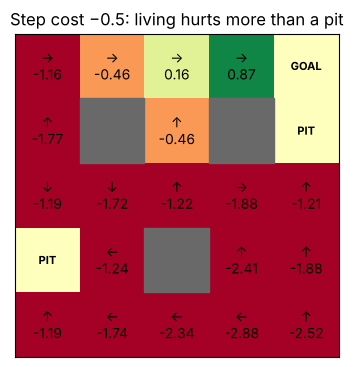

In [12]:
# Exercise 2 — solution
STEP_COST = -0.5
V2, pi2, _ = value_iteration()
show_grid(V2, pi2, "Step cost −0.5: living hurts more than a pit")
STEP_COST = -0.04

With each step costing −0.5, the walk to the goal costs more than the −1 of a pit. From several squares the "optimal" agent now **heads straight into the nearest pit**. The maths is correct. The **reward design** is the problem. This is the core lesson of reward hacking: an agent optimises exactly what you reward, not what you meant.

**Next:** [19 · Recommender Systems](19_recommender_systems.ipynb) — how platforms decide what to show you.

*Going deeper / interview prep:* `RL_Interview_Notes.md` — Part 1 (MDPs, Bellman), Part 2 (dynamic programming), Part 3 (MC, TD, TD(λ)), Part 4 (on- vs off-policy, the cliff, maximisation bias, exploration, Dyna-Q), Part 5 (function approximation, deadly triad, DQN), Part 6 (policy gradients, baselines, actor-critic, GAE, TRPO/PPO), §7.4 (RLHF) · code: `rl_from_scratch.py` · `ml_from_scratch_part2.py` → `MultiArmedBandit`, `QLearning`.